# ECS708 Machine Learning: Fashion-MNIST investigation

**Research question.** What structure exists in Fashion-MNIST, how can different machine-learning models exploit that structure, and what do their successes and failures teach us about the data and its representations?

**How to read this notebook.** Headings and figure captions carry the coursework task IDs (e.g. *addresses 1.4*). Every key result states its **split, metric, configuration and variability**. The notebook is meant to run top to bottom with *Restart and run all* (about 6 to 8 minutes on a 2-core CPU, no GPU). All experiments are logged in `results/experiment_register.csv` (rule R3); the fixed partitions are in `splits/` (rule R1, Part 0).

**Contents so far:** Part 0 (setup), Part 1 (classical classification). Later parts are appended below.

## Part 0: setup, data roles and computing (addresses 0.1, 0.2)

* **Data.** Fashion-MNIST, 28×28 greyscale, 10 classes; 60,000 official train and 10,000 official test images.
* **Partitions (frozen).** The official training set is split once, stratified and seeded (**seed 708**), into **50,000 train / 10,000 validation** (`splits/splits_seed708.npz`, created by `scripts/make_splits.py`; re-running that script reproduces the files exactly and refuses to overwrite different ones). The 10,000 official test images are **sealed**: the variable holding them is not touched until the guarded final section of Part 1 (rules R1, R6, R7).
* **Data roles.** *Train* fits parameters. *Validation* chooses hyperparameters (regularisation strength, tree depth, smoothing, decision thresholds). *Test* gives the final estimate only.
* **Preprocessing.** Pixels are divided by 255, so features lie in [0, 1]. This is a fixed transform that uses no data statistics, so there is nothing fitted that could leak between partitions (rule R2). No scaler is fitted anywhere in Part 1.
* **CPU option.** Not used: the full 50,000 training images fit comfortably on a CPU (see fit times below).

In [1]:
import sys, os, platform, time, json, warnings
from pathlib import Path
ROOT = Path.cwd()
assert (ROOT / "src" / "data.py").exists(), "Run this notebook from the repository root (the folder that contains src/)."
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, log_loss

from src.data import CLASS_NAMES, SEED, get_partitions, split_summary
from src import evaluation as ev

np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = ROOT / "figures"; RES_DIR = ROOT / "results" / "part1"
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(parents=True, exist_ok=True)
SHORT = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

FIG_INDEX = []
def save_fig(fig, name, tasks, caption):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIG_INDEX.append({"file": f"figures/{path.name}", "tasks": tasks, "produced_by": "ecs708_fashion_mnist.ipynb", "caption": caption})

def cpu_name():
    try: return next(l.split(":")[1].strip() for l in open("/proc/cpuinfo") if "model name" in l)
    except Exception: return platform.processor() or "unknown"

print("Hardware (0.2):", cpu_name(), "|", os.cpu_count(), "logical CPUs | no GPU used")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

parts = get_partitions()                    # float32 in [0,1], shape (N, 784); labels int64
Xtr, ytr = parts["train"]; Xva, yva = parts["val"]
_sealed_test = parts.pop("test")            # SEALED: not used again until the guarded final section (R1, R6, R7)
summary = split_summary()
print(f"seed {summary['seed']} | train {Xtr.shape} | validation {Xva.shape} | test sealed")
print("train class counts     :", np.bincount(ytr).tolist())
print("validation class counts:", np.bincount(yva).tolist())

Hardware (0.2): Intel(R) Xeon(R) Processor @ 2.30GHz | 2 logical CPUs | no GPU used
Python 3.13.18 | numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5


seed 708 | train (50000, 784) | validation (10000, 784) | test sealed
train class counts     : [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


---
# Part 1: Classical classification

*Guiding question: how do different classifiers use the same data, and what can their errors tell us?*

## Design of the experiments (rules R1, R3, R4)

| Item | Choice |
|---|---|
| Data | Same 50,000 training images and same 10,000 validation images for every model (R4). Test sealed. |
| Models | Multinomial logistic regression (L2), decision tree (entropy), Gaussian naive Bayes (see 1.1). |
| Complexity knob (1.4) | LR: inverse regularisation strength `C`. Tree: `max_depth`. NB: `var_smoothing`. |
| Selection rule | Highest **validation** accuracy; for LR and the tree, a simpler setting is preferred if it is within 0.1 percentage points of the best (so a tie is not decided by noise). |
| Metrics | Accuracy; per-class precision, recall, F1 with **support** (1.2); confusion matrices (1.3); ROC and expected cost for a binary problem (1.5). |
| Variability | LR (L-BFGS from zero initialisation) and naive Bayes are deterministic. The tree has random tie-breaking between equally good splits, so the selected depth is refitted with 3 seeds. The remaining uncertainty is *sampling* uncertainty of the 10,000 validation images, shown as 95% Wilson intervals. |
| Order | 1.4 is run **first** because it selects the configuration used in 1.2, 1.3 and 1.5. |

**Disclosure (R7).** Before the formal runs below, one quick unrecorded scoping run on the validation data was used only to check that the models fit in reasonable time on this CPU. No setting below was chosen from it; all selections come from the registered sweeps.

## 1.1 Models and justification

**What the data look like.** 784 numeric features in [0, 1] (pixel intensities), 10 balanced classes (5,000 training images each), no missing values and no categorical features. Neighbouring pixels are strongly correlated, images are roughly centred, and classes differ mostly in *silhouette* (trousers have a gap between the legs; bags and sandals have very different outlines; shirts, T-shirts, pullovers and coats have similar upper-body outlines).

I chose three methods taught in the module that use that data in three different ways, so that their errors can be compared (guiding question):

| | **Logistic regression** (softmax / MaxEnt, Week 4) | **Decision tree** (Week 5) | **Gaussian naive Bayes** (Week 5) |
|---|---|---|---|
| **How it predicts** | One weight vector per class: score *z<sub>k</sub> = w<sub>k</sub>·x + b<sub>k</sub>*; *p(k\|x) = softmax(z)*; predict the largest. Uses **all pixels at once**; boundaries between classes are linear. | A chain of yes/no tests on **one pixel at a time** (*is pixel j brighter than t?*) ending in a leaf that predicts the majority class. Can combine pixels non-linearly through nested tests. | For each class, a Gaussian per pixel. Predict the class maximising *log prior + Σ<sub>j</sub> log N(x<sub>j</sub>; μ<sub>jk</sub>, σ²<sub>jk</sub>)*: it **multiplies per-pixel evidence as if pixels were independent given the class**. |
| **How it is fitted** | Minimise negative log-likelihood plus an L2 penalty. Convex, no closed form, so it is solved iteratively using gradients (scikit-learn uses L-BFGS, a gradient-based method, rather than plain gradient descent). | Greedy recursion: pick the pixel and threshold with the largest **information gain** (entropy reduction), split, repeat on each side until leaves are pure or a limit is reached. | Closed form, one pass: class frequencies, and per class and pixel the sample mean and variance (maximum likelihood). |
| **How complexity is controlled** | `C` = inverse penalty strength. Small `C` forces small weights (smoother, less confident, simpler); large `C` lets weights grow. | `max_depth` (also minimum leaf size or pruning). Depth limits how many tests, hence how many regions, the tree can carve out. | Few knobs. `var_smoothing` adds a fraction of the largest pixel variance to every variance, which prevents near-zero variances from producing extreme likelihoods (it plays a similar protective role to the λ-smoothing of counts in the lecture, but it is not the same formula). |
| **Why for this data** | Strong linear baseline for pixels; weights can be viewed as 28×28 templates; gives class probabilities, which Task 1.5 needs. | Very different inductive bias (axis-aligned single-pixel tests, interpretable splits); the lecture's overfitting story applies directly to depth. | A deliberately simple generative baseline. Its independence assumption is clearly violated by neighbouring pixels, so it shows what ignoring pixel dependence costs. |

**Fair comparison caveats (R4).** All three see identical inputs. LR is iterative and capped at 400 L-BFGS iterations (convergence is recorded below); the tree and NB are not iterative, so "equal training budget" is not exactly defined across the three.

## 1.4 Complexity study (run first; it selects the configurations used in 1.2, 1.3 and 1.5)

**Question.** How does model complexity affect generalisation, i.e. how do training and validation performance move as the complexity knob changes?

**Hypotheses (written from the lecture before the formal runs).**
* *H-LR:* a very small `C` (strong penalty) under-fits, with low and similar train and validation accuracy. Raising `C` raises training accuracy faster than validation accuracy, so the train-validation gap widens; the weight norm and the average confidence of the predictions grow with `C` (lecture: larger weights, steeper sigmoid, more confident).
* *H-DT:* depth 1 to 2 under-fits; training accuracy rises towards 100% as depth is unrestricted, while validation accuracy rises and then flattens, so the gap keeps widening after a moderate depth (over-fitting).
* *H-NB:* much lower accuracy than LR because pixels are not conditionally independent; stronger variance smoothing may help.

**Fixed:** data, preprocessing, validation images, seed 708. **Changed:** one knob per model. **Metric:** accuracy on train and on validation (plus log-loss for LR). Each fit is one row in the experiment register.

In [2]:
ev.reset_register("P1-")        # idempotent: re-running the notebook never duplicates Part 1 rows
MODELS = {}                     # (family, setting) -> fitted model (all fitted on the 50,000 training images only)
HYP = {
 "LR": "Small C under-fits; larger C widens the train-validation gap; weight norm and confidence grow with C.",
 "DT": "Shallow trees under-fit; train accuracy -> 100% with depth while validation flattens (over-fitting).",
 "NB": "Independence assumption makes accuracy far lower than LR; variance smoothing may help.",
}
SEED_NOTE = "seed 708"

# ---------------- Logistic regression: sweep C (inverse L2 strength) -----------------
LR_C = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
LR_MAXIT = 400
rows = []
for i, C in enumerate(LR_C, 1):
    m, sec, warns = ev.timed_fit(LogisticRegression(C=C, max_iter=LR_MAXIT), Xtr, ytr)
    proba = m.predict_proba(Xva)
    r = dict(C=C, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, proba),
             weight_norm=float(np.linalg.norm(m.coef_)), mean_top_prob=float(proba.max(1).mean()),
             n_iter=int(np.max(m.n_iter_)), converged=bool(np.max(m.n_iter_) < LR_MAXIT), fit_s=sec)
    rows.append(r); MODELS[("LR", C)] = m
    ev.log_experiment(id=f"P1-LR-{i:02d}", part_task="1.4", question="How does L2 strength (C) affect train/val accuracy?",
        hypothesis=HYP["LR"], changed_variable="C", fixed_conditions=f"multinomial LR, lbfgs, max_iter={LR_MAXIT}, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"C={C}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; converged={r['converged']}",
        output_path="results/part1/sweep_logreg.csv", notes=f"fit {sec:.0f}s; weight_norm={r['weight_norm']:.1f}; " + ("; ".join(warns) if warns else "no warnings"))
lr_df = pd.DataFrame(rows)

# ---------------- Decision tree: sweep max_depth -----------------
DT_DEPTH = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for i, d in enumerate(DT_DEPTH, 1):
    m, sec, _ = ev.timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED), Xtr, ytr)
    r = dict(max_depth="None" if d is None else d, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva),
             n_leaves=int(m.get_n_leaves()), actual_depth=int(m.get_depth()), fit_s=sec)
    rows.append(r); MODELS[("DT", d)] = m
    ev.log_experiment(id=f"P1-DT-{i:02d}", part_task="1.4", question="How does tree depth affect train/val accuracy?",
        hypothesis=HYP["DT"], changed_variable="max_depth", fixed_conditions="entropy criterion, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (tie-breaking)", configuration=f"max_depth={d}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; leaves={r['n_leaves']}",
        output_path="results/part1/sweep_tree.csv", notes=f"fit {sec:.0f}s; actual depth {r['actual_depth']}")
dt_df = pd.DataFrame(rows)

# ---------------- Gaussian naive Bayes: sweep var_smoothing -----------------
NB_VS = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 3e-1, 1.0]
rows = []
for i, v in enumerate(NB_VS, 1):
    m, sec, _ = ev.timed_fit(GaussianNB(var_smoothing=v), Xtr, ytr)
    proba = m.predict_proba(Xva)
    r = dict(var_smoothing=v, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, np.clip(proba, 1e-15, 1)),
             mean_top_prob=float(proba.max(1).mean()), fit_s=sec)
    rows.append(r); MODELS[("NB", v)] = m
    ev.log_experiment(id=f"P1-NB-{i:02d}", part_task="1.4", question="How does variance smoothing affect train/val accuracy?",
        hypothesis=HYP["NB"], changed_variable="var_smoothing", fixed_conditions="Gaussian NB, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"var_smoothing={v}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}",
        output_path="results/part1/sweep_nb.csv", notes=f"fit {sec:.1f}s")
nb_df = pd.DataFrame(rows)

lr_df.to_csv(RES_DIR / "sweep_logreg.csv", index=False); dt_df.to_csv(RES_DIR / "sweep_tree.csv", index=False); nb_df.to_csv(RES_DIR / "sweep_nb.csv", index=False)
fmt = {"train_acc": "{:.4f}", "val_acc": "{:.4f}", "val_logloss": "{:.4f}", "weight_norm": "{:.1f}", "mean_top_prob": "{:.3f}", "fit_s": "{:.1f}", "C": "{:g}", "var_smoothing": "{:g}"}
print("Logistic regression (train 50k; accuracy on train and on validation 10k)"); display(lr_df.style.format(fmt).hide(axis="index"))
print("Decision tree (entropy)"); display(dt_df.style.format(fmt).hide(axis="index"))
print("Gaussian naive Bayes"); display(nb_df.style.format(fmt).hide(axis="index"))

Logistic regression (train 50k; accuracy on train and on validation 10k)


C,train_acc,val_acc,val_logloss,weight_norm,mean_top_prob,n_iter,converged,fit_s
0.0001,0.7562,0.7509,0.8998,1.7,0.515,87,True,6.8
0.001,0.8217,0.8162,0.5708,3.7,0.713,146,True,9.8
0.01,0.8569,0.8487,0.4413,7.7,0.807,193,True,12.6
0.1,0.8747,0.8553,0.4031,16.7,0.847,302,True,22.1
1,0.8820,0.8528,0.4172,33.7,0.866,400,False,27.2
10,0.8828,0.8528,0.4255,39.4,0.871,400,False,28.1


Decision tree (entropy)


max_depth,train_acc,val_acc,n_leaves,actual_depth,fit_s
1,0.1989,0.1985,2,1,1.4
2,0.3422,0.3434,4,2,2.7
3,0.5164,0.5168,8,3,4.0
4,0.6776,0.6814,16,4,5.4
5,0.7174,0.7182,32,5,6.9
6,0.7447,0.7411,64,6,8.1
8,0.8040,0.7866,235,8,10.9
10,0.8508,0.8093,655,10,13.6
12,0.8932,0.8184,1238,12,16.4
15,0.9493,0.8182,2333,15,18.7


Gaussian naive Bayes


var_smoothing,train_acc,val_acc,val_logloss,mean_top_prob,fit_s
1e-09,0.5940,0.5939,6.3605,0.998,0.2
1e-07,0.6124,0.6118,6.0854,0.998,0.2
1e-05,0.6340,0.6329,5.7778,0.999,0.2
0.001,0.6601,0.6567,5.3752,0.998,0.2
0.01,0.6727,0.6698,5.1396,0.998,0.2
0.1,0.6783,0.6746,4.9744,0.997,0.2
0.3,0.6701,0.6679,4.9306,0.994,0.2
1,0.6504,0.6489,4.7704,0.985,0.2


In [3]:
# ---------------- Selection on VALIDATION accuracy (rule R1) -----------------
def pick_simplest_within(df, key, tol=0.001):
    # rows are ordered from simplest to most complex; take the first within `tol` of the best validation accuracy
    best = df["val_acc"].max()
    return df[df["val_acc"] >= best - tol].iloc[0][key]

SEL = {
    "LR": float(pick_simplest_within(lr_df, "C")),
    "DT": pick_simplest_within(dt_df, "max_depth"),
    "NB": float(nb_df.loc[nb_df["val_acc"].idxmax(), "var_smoothing"]),
}
SEL["DT"] = None if SEL["DT"] == "None" else int(SEL["DT"])
SEL_MODELS = {"LR": MODELS[("LR", SEL["LR"])], "DT": MODELS[("DT", SEL["DT"])], "NB": MODELS[("NB", SEL["NB"])]}
LABEL = {"LR": f"Logistic regression (C={SEL['LR']:g})", "DT": f"Decision tree (max_depth={SEL['DT']})", "NB": f"Gaussian NB (var_smoothing={SEL['NB']:g})"}
print("Selected on validation accuracy:"); [print("  ", v) for v in LABEL.values()]

# ---------------- Tree variability: refit the selected depth with 3 seeds (R5 spirit) -----------------
tree_seed_rows = []
for s in [SEED, 1, 2]:
    m, sec, _ = ev.timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=SEL["DT"], random_state=s), Xtr, ytr)
    tree_seed_rows.append({"seed": s, "train_acc": m.score(Xtr, ytr), "val_acc": m.score(Xva, yva), "n_leaves": int(m.get_n_leaves())})
    ev.log_experiment(id=f"P1-DTSEED-{s}", part_task="1.2/1.4", question="How much does the selected tree depend on the seed (tie-breaking)?",
        hypothesis="Small effect: ties between equally good splits are rare for continuous-valued pixels.", changed_variable="random_state",
        fixed_conditions=f"entropy, max_depth={SEL['DT']}", split="fit train 50k; validation 10k", seed=str(s), configuration=f"max_depth={SEL['DT']}",
        metric="validation accuracy", result=f"{tree_seed_rows[-1]['val_acc']:.4f}", output_path="results/part1/tree_seeds.csv", notes=f"fit {sec:.0f}s")
tree_seeds = pd.DataFrame(tree_seed_rows); tree_seeds.to_csv(RES_DIR / "tree_seeds.csv", index=False)
display(tree_seeds.style.format({"train_acc": "{:.4f}", "val_acc": "{:.4f}"}).hide(axis="index"))
print(f"Tree validation accuracy over 3 seeds: mean {tree_seeds.val_acc.mean():.4f}, sample std (ddof=1) {tree_seeds.val_acc.std(ddof=1):.4f}")

Selected on validation accuracy:
   Logistic regression (C=0.1)
   Decision tree (max_depth=12)
   Gaussian NB (var_smoothing=0.1)


seed,train_acc,val_acc,n_leaves
708,0.8932,0.8184,1238
1,0.8930,0.8179,1237
2,0.8932,0.8179,1241


Tree validation accuracy over 3 seeds: mean 0.8181, sample std (ddof=1) 0.0003


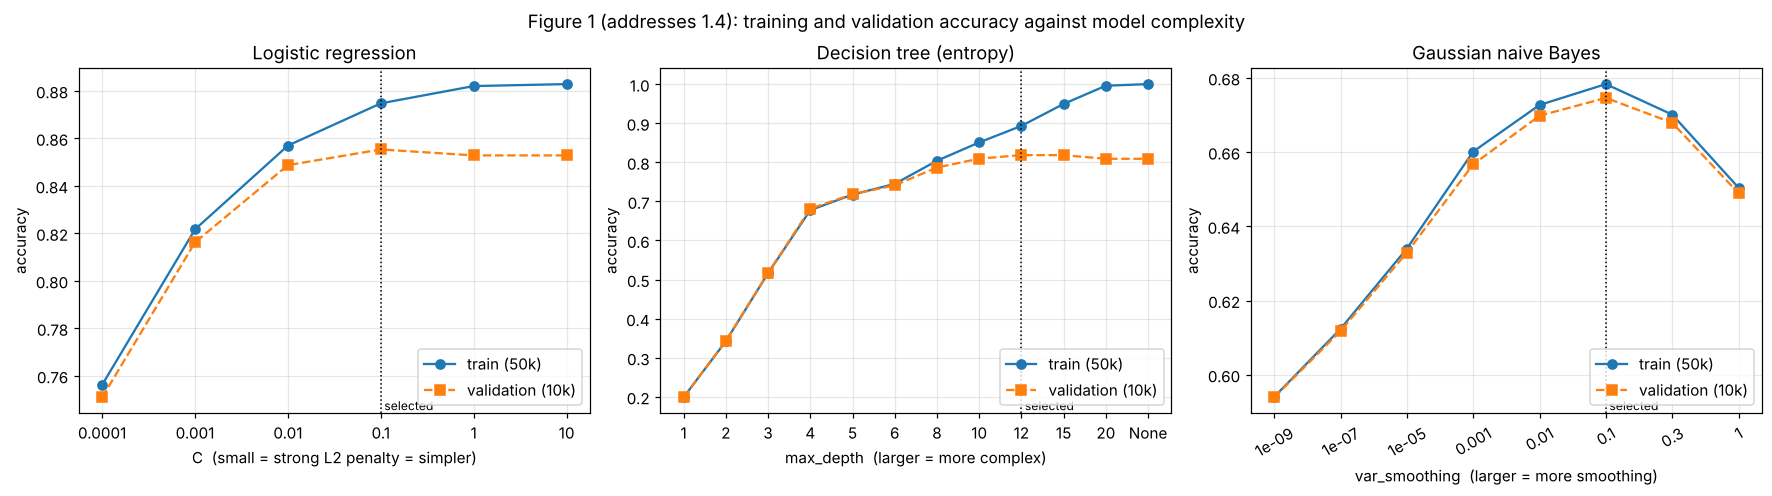

In [4]:
# ---------------- Figure 1: train vs validation across the complexity knob (addresses 1.4) -----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)

x = np.arange(len(lr_df)); ax[0].plot(x, lr_df.train_acc, "o-", label="train (50k)"); ax[0].plot(x, lr_df.val_acc, "s--", label="validation (10k)")
ax[0].set_xticks(x, [f"{c:g}" for c in lr_df.C]); ax[0].set_xlabel("C  (small = strong L2 penalty = simpler)"); ax[0].set_title("Logistic regression")
ax[0].axvline(list(lr_df.C).index(SEL["LR"]), color="k", ls=":", lw=1); ax[0].text(list(lr_df.C).index(SEL["LR"]), ax[0].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(dt_df)); ax[1].plot(x, dt_df.train_acc, "o-", label="train (50k)"); ax[1].plot(x, dt_df.val_acc, "s--", label="validation (10k)")
ax[1].set_xticks(x, [str(d) for d in dt_df.max_depth], rotation=0); ax[1].set_xlabel("max_depth  (larger = more complex)"); ax[1].set_title("Decision tree (entropy)")
sel_pos = [str(d) for d in dt_df.max_depth].index(str(SEL["DT"])); ax[1].axvline(sel_pos, color="k", ls=":", lw=1); ax[1].text(sel_pos, ax[1].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(nb_df)); ax[2].plot(x, nb_df.train_acc, "o-", label="train (50k)"); ax[2].plot(x, nb_df.val_acc, "s--", label="validation (10k)")
ax[2].set_xticks(x, [f"{v:g}" for v in nb_df.var_smoothing], rotation=30); ax[2].set_xlabel("var_smoothing  (larger = more smoothing)"); ax[2].set_title("Gaussian naive Bayes")
ax[2].axvline(list(nb_df.var_smoothing).index(SEL["NB"]), color="k", ls=":", lw=1); ax[2].text(list(nb_df.var_smoothing).index(SEL["NB"]), ax[2].get_ylim()[0], " selected", va="bottom", fontsize=8)

for a in ax: a.set_ylabel("accuracy"); a.legend(loc="lower right")
fig.suptitle("Figure 1 (addresses 1.4): training and validation accuracy against model complexity", fontsize=12)
save_fig(fig, "fig1_complexity_train_vs_val", "1.4", "Train (solid, circles) and validation (dashed, squares) accuracy against the complexity knob of each model; dotted line = value selected on validation.")
plt.show()

**Figure 1 (addresses 1.4).** Training accuracy (solid line, circles) and validation accuracy (dashed line, squares) against the complexity knob of each model. Fit on the 50,000 training images, evaluated on the same 10,000 validation images, seed 708. The dotted vertical line marks the value selected on validation.

### Interpretation of 1.4
**Logistic regression (H-LR largely supported).** With the strongest penalty (C=0.0001) train and validation accuracy are both low (0.756 / 0.751), a gap of 0.005. Raising C raises training accuracy faster than validation accuracy: the gap grows to 0.019 at C=0.1 and 0.029 at C=1. Validation accuracy peaks at **C=0.1 (0.8553)**; at C=1 and C=10 it is slightly lower (0.8528) while training accuracy keeps rising, and validation log-loss is lowest at C=0.1 (0.403) and increases afterwards (0.417, 0.426). The mechanism predicted from the lecture is visible: the weight norm grows from 1.7 to 39.4 and the mean top-class probability from 0.52 to 0.87. The over-fitting here is mild: a 0.2 to 0.3 point drop in validation accuracy, which is within the sampling interval of about ±0.7 points, so I do not claim a real difference between C=0.1, 1 and 10 in accuracy; the log-loss gives somewhat firmer support for C=0.1. **Caveat:** C=1 and C=10 hit the 400-iteration limit without converging, so those two fits are not exact optima. C=0.1 converged (302 iterations) and was selected.

**Decision tree (H-DT supported).** Depth 1 and 2 under-fit badly (0.199 and 0.343 validation, since 2 and 4 leaves cannot separate 10 classes). Validation accuracy rises steeply to depth 10 (0.809), peaks around depth 12 to 15 (0.8184 / 0.8182) and then declines slightly (0.809 at depth 20 and 0.8089 unlimited), while training accuracy rises to 0.9959 at depth 20 and 1.000 for the unrestricted tree (3,469 leaves). The train-validation gap is about 0.00 at depth 5, 0.07 at depth 12 and 0.19 at unlimited depth. Selected on validation: **max_depth=12** (the simplest depth within 0.1 points of the best). Seed sensitivity is tiny: three seeds give validation accuracy 0.8184, 0.8179, 0.8179 (sample std about 0.0003).

**Naive Bayes (H-NB supported).** Accuracy is far below LR (best 0.6746 at var_smoothing=0.1, versus 0.5939 with almost no smoothing), so smoothing helps by about 8 points but does not close the gap. Its probabilities are extremely over-confident: the mean top-class probability is about 0.99 while accuracy is 0.67, and validation log-loss is about 5.0, versus 0.40 for LR. This is what ignoring pixel dependence does: many correlated pixels each contribute 'independent' evidence, so the evidence is counted many times.

**Limits of this evidence.** One fixed split, so the comparisons between settings within about 0.5 points are not reliable; the knob grids are coarse; the tree's depth effect is measured with a single data split.

## 1.2 Metrics: overall accuracy and a class-level view

All numbers in this section are on the **validation** set (10,000 images, 1,000 per class), for the three models with the settings selected in 1.4. They are single fits (LR and NB are deterministic; the tree's seed sensitivity is in the table above). The **support** column gives the number of images of each class, so a recall of, say, 0.80 can be read as 800 of 1,000 images; **precision** is TP divided by *all images predicted as that class* (shown too, because it has a different denominator).

In [5]:
PRED_VA = {k: m.predict(Xva) for k, m in SEL_MODELS.items()}
n = len(yva)
rows = []
for k, p in PRED_VA.items():
    correct = int((p == yva).sum()); lo, hi = ev.wilson_interval(correct, n)
    t = ev.per_class_table(yva, p)
    rows.append({"model": LABEL[k], "correct / n": f"{correct} / {n}", "accuracy": correct / n, "95% interval (sampling)": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": t["F1"].mean()})
overall = pd.DataFrame(rows)
overall.to_csv(RES_DIR / "overall_validation.csv", index=False)
print("Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)")
display(overall.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}"}).hide(axis="index"))

tables = {k: ev.per_class_table(yva, p) for k, p in PRED_VA.items()}
wide = tables["LR"][["class", "support"]].copy()
for k in ["LR", "DT", "NB"]:
    wide[f"{k} recall"] = tables[k]["recall"]; wide[f"{k} precision"] = tables[k]["precision"]; wide[f"{k} F1"] = tables[k]["F1"]
wide.to_csv(RES_DIR / "per_class_validation.csv", index=False)
print("Class-level view on VALIDATION (support = images per class)")
display(wide.style.format({c: "{:.3f}" for c in wide.columns if c not in ("class", "support")}).hide(axis="index"))
for k in ["LR", "DT", "NB"]:
    ev.log_experiment(id=f"P1-EVAL-{k}", part_task="1.2", question="Overall and per-class performance of the selected model on validation",
        hypothesis="Footwear and trousers/bags are easy; upper-body garments (shirt, T-shirt, pullover, coat) are hard.", changed_variable="model family",
        fixed_conditions="same 50k train / same 10k validation images / pixels/255", split="validation 10k", seed=SEED_NOTE, configuration=LABEL[k],
        metric="accuracy; per-class precision/recall/F1 with support", result=f"acc={overall.set_index('model').loc[LABEL[k], 'accuracy']:.4f}",
        output_path="results/part1/per_class_validation.csv", notes="single deterministic fit" if k != "DT" else "tree seed spread in tree_seeds.csv")

Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)


model,correct / n,accuracy,95% interval (sampling),macro-F1
Logistic regression (C=0.1),8553 / 10000,0.8553,"[0.8483, 0.8621]",0.8547
Decision tree (max_depth=12),8184 / 10000,0.8184,"[0.8107, 0.8258]",0.8168
Gaussian NB (var_smoothing=0.1),6746 / 10000,0.6746,"[0.6654, 0.6837]",0.6618


Class-level view on VALIDATION (support = images per class)


class,support,LR recall,LR precision,LR F1,DT recall,DT precision,DT F1,NB recall,NB precision,NB F1
T-shirt/top,1000,0.831,0.788,0.809,0.786,0.737,0.761,0.685,0.753,0.717
Trouser,1000,0.975,0.976,0.975,0.951,0.972,0.962,0.936,0.918,0.927
Pullover,1000,0.758,0.770,0.764,0.773,0.689,0.729,0.421,0.670,0.517
Dress,1000,0.860,0.851,0.856,0.834,0.835,0.834,0.867,0.585,0.698
Coat,1000,0.777,0.757,0.767,0.732,0.688,0.709,0.671,0.516,0.583
Sandal,1000,0.928,0.956,0.942,0.881,0.923,0.901,0.465,0.614,0.529
Shirt,1000,0.590,0.634,0.611,0.493,0.631,0.554,0.187,0.333,0.239
Sneaker,1000,0.932,0.920,0.926,0.887,0.875,0.881,0.946,0.586,0.724
Bag,1000,0.946,0.950,0.948,0.924,0.931,0.927,0.748,0.913,0.822
Ankle boot,1000,0.956,0.942,0.949,0.923,0.899,0.911,0.820,0.906,0.861


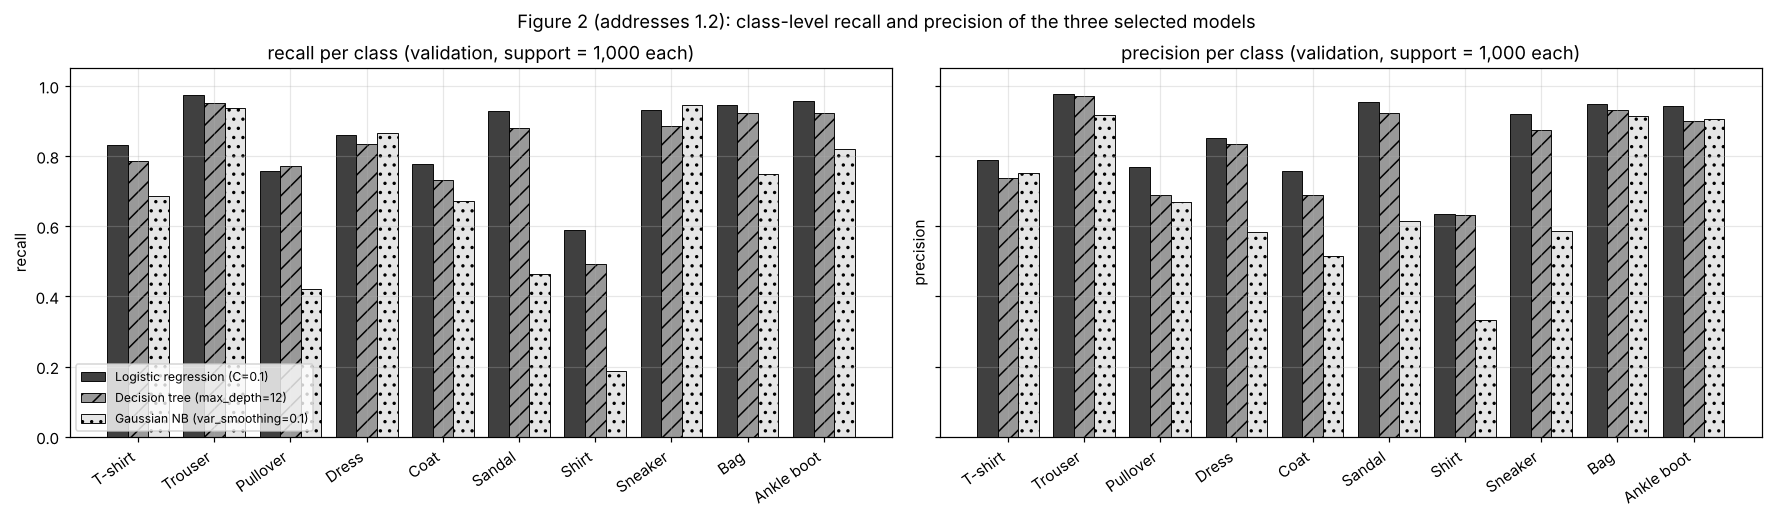

In [6]:
# ---------------- Figure 2: class-level recall and precision (addresses 1.2) -----------------
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), constrained_layout=True, sharey=True)
w = 0.27; xs = np.arange(10); hatches = {"LR": "", "DT": "//", "NB": ".."}; shade = {"LR": "0.25", "DT": "0.6", "NB": "0.9"}
for a, col in zip(ax, ["recall", "precision"]):
    for j, k in enumerate(["LR", "DT", "NB"]):
        bars = a.bar(xs + (j - 1) * w, tables[k][col], w, label=LABEL[k], hatch=hatches[k], facecolor=shade[k], edgecolor="k", lw=0.6)
    a.set_xticks(xs, SHORT, rotation=35, ha="right"); a.set_ylim(0, 1.05); a.set_title(f"{col} per class (validation, support = 1,000 each)"); a.set_ylabel(col)
ax[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure 2 (addresses 1.2): class-level recall and precision of the three selected models", fontsize=12)
save_fig(fig, "fig2_per_class_recall_precision", "1.2", "Recall and precision per class on the validation set for the three selected models (patterns distinguish the models).")
plt.show()

**Figure 2 (addresses 1.2).** Recall (left) and precision (right) per class on the 10,000 validation images (1,000 per class). Bar patterns, not colour alone, identify the model. Single fits with the settings selected in 1.4.

### Interpretation of 1.2
On validation, logistic regression (C=0.1) reaches **0.8553** accuracy (95% interval [0.8483, 0.8621]), the tree (depth 12) **0.8184** ([0.8107, 0.8258]) and naive Bayes **0.6746** ([0.6654, 0.6837]); chance is 0.10. The intervals of LR and the tree do not overlap, but they describe sampling uncertainty of one validation set and the models are compared on the same images, so this indicates that LR is better here, not by how much on new data. The tree's seed spread is about 0.0003, far smaller than this gap.

The class-level view shows that the average hides a large spread. For LR, recall ranges from 0.975 (Trouser) and 0.956 (Ankle boot) down to **0.590 for Shirt**, then Pullover 0.758 and Coat 0.777 (each class has support 1,000, so Shirt means 590 of 1,000 found). The same classes are weakest for the tree (Shirt recall 0.493, Pullover 0.773, Coat 0.732) and the pattern holds for NB, where it is more extreme (Shirt recall 0.187, F1 0.24). The ordering of difficulty is therefore similar across very different models, which suggests the difficulty comes from the data (similar upper-body silhouettes) rather than from one model's weakness.

Models differ in *which* error they make: NB has high recall but low precision for Dress (0.867 / 0.585) and Sneaker (0.946 / 0.586): it predicts those classes too often. Pullover and Sandal have recall near 0.4 to 0.5 for NB although they are easy for LR. Macro-F1 follows accuracy closely here because classes are exactly balanced.

## 1.3 Error analysis

**Question.** Which classes are easy or hard, which classes are confused with which, and do the two main models (logistic regression and decision tree) fail on the *same* images?

**Hypothesis.** Errors concentrate among upper-body garments with similar silhouettes (T-shirt, shirt, pullover, coat, and dress), while trousers, bags and footwear are rarely confused with other groups. Footwear errors should stay inside the footwear group.

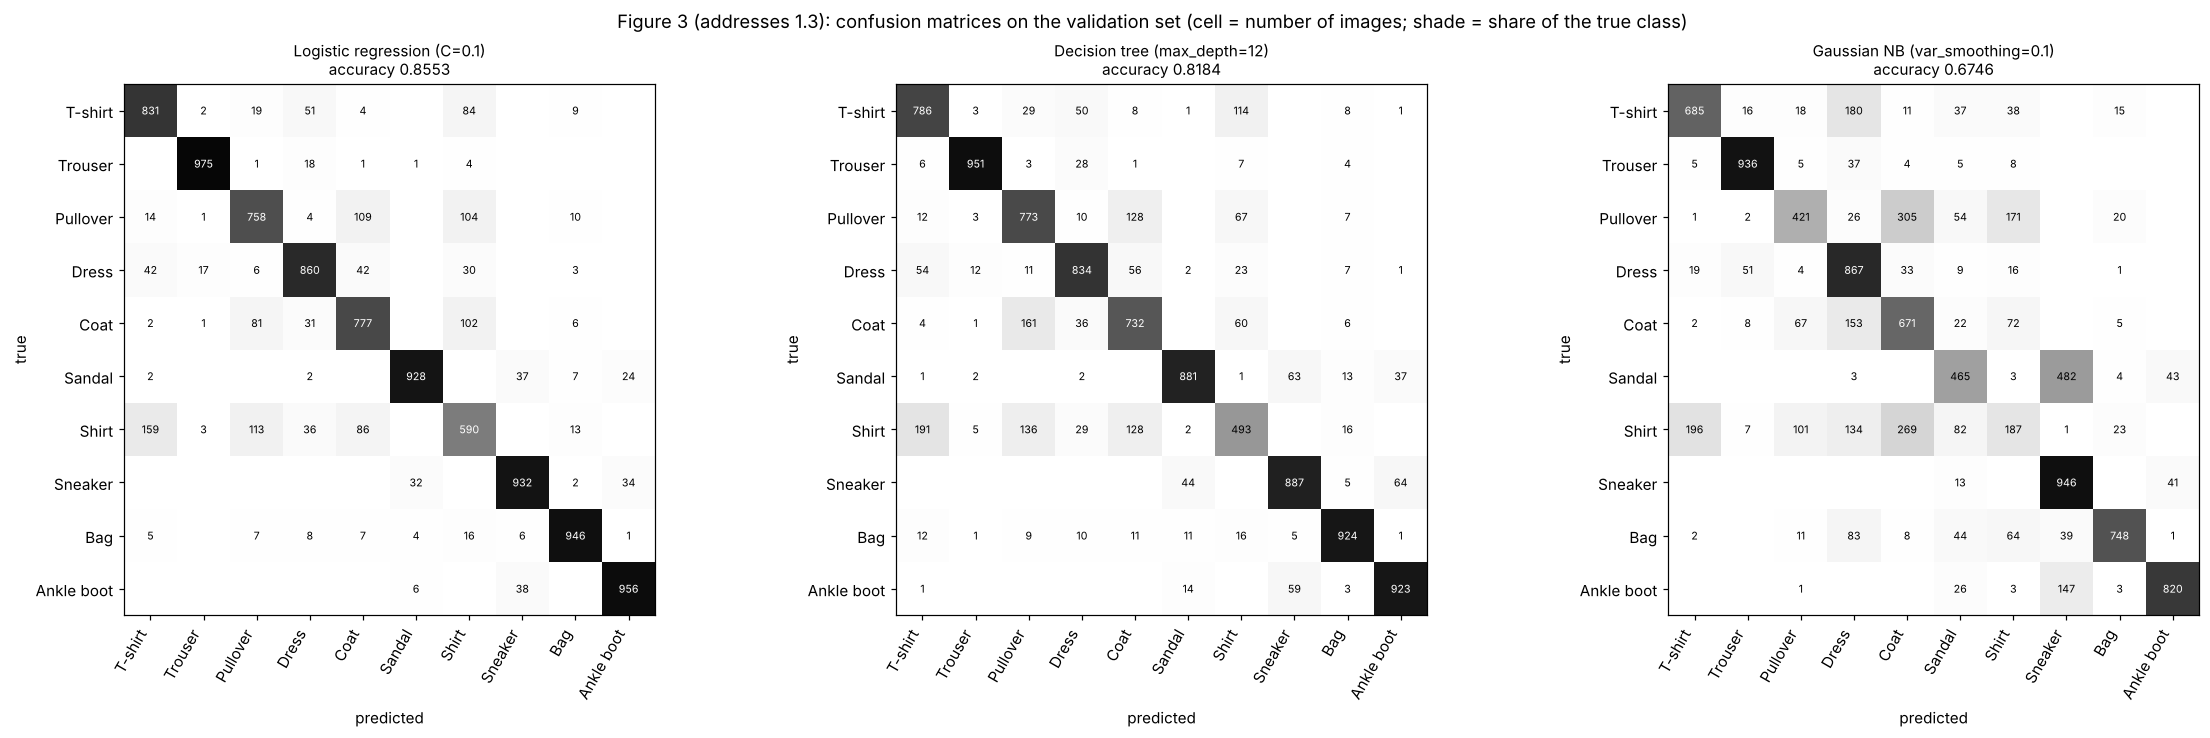

Most frequent confusions, Logistic regression (C=0.1) (validation):


true,predicted,count,share of true class
Shirt,T-shirt/top,159,0.159
Shirt,Pullover,113,0.113
Pullover,Coat,109,0.109
Pullover,Shirt,104,0.104
Coat,Shirt,102,0.102
Shirt,Coat,86,0.086


Most frequent confusions, Decision tree (max_depth=12) (validation):


true,predicted,count,share of true class
Shirt,T-shirt/top,191,0.191
Coat,Pullover,161,0.161
Shirt,Pullover,136,0.136
Pullover,Coat,128,0.128
Shirt,Coat,128,0.128
T-shirt/top,Shirt,114,0.114


Most frequent confusions, Gaussian NB (var_smoothing=0.1) (validation):


true,predicted,count,share of true class
Sandal,Sneaker,482,0.482
Pullover,Coat,305,0.305
Shirt,Coat,269,0.269
Shirt,T-shirt/top,196,0.196
T-shirt/top,Dress,180,0.180
Pullover,Shirt,171,0.171


In [7]:
# ---------------- Figure 3: row-normalised confusion matrices (addresses 1.3) -----------------
fig, ax = plt.subplots(1, 3, figsize=(21, 6.6), constrained_layout=True)
CMS = {}
for a, k in zip(ax, ["LR", "DT", "NB"]):
    cm = confusion_matrix(yva, PRED_VA[k], labels=range(10)); CMS[k] = cm
    a.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            v = cm[i, j]
            if v > 0: a.text(j, i, f"{v}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
    a.set_xticks(range(10), SHORT, rotation=60, ha="right"); a.set_yticks(range(10), SHORT); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
    a.set_title(f"{LABEL[k]}\naccuracy {np.trace(cm) / cm.sum():.4f}", fontsize=10)
fig.suptitle("Figure 3 (addresses 1.3): confusion matrices on the validation set (cell = number of images; shade = share of the true class)", fontsize=12)
save_fig(fig, "fig3_confusion_matrices", "1.3", "Confusion matrices (counts; shading = row-normalised share) for the three selected models on the validation set.")
plt.show()

for k in ["LR", "DT", "NB"]:
    print(f"Most frequent confusions, {LABEL[k]} (validation):")
    display(ev.top_confusions(yva, PRED_VA[k], 6).style.format({"share of true class": "{:.3f}"}).hide(axis="index"))

Agreement of LR and tree on the SAME 10,000 validation images


,DT correct,DT wrong
LR correct,7653,531
LR wrong,900,916


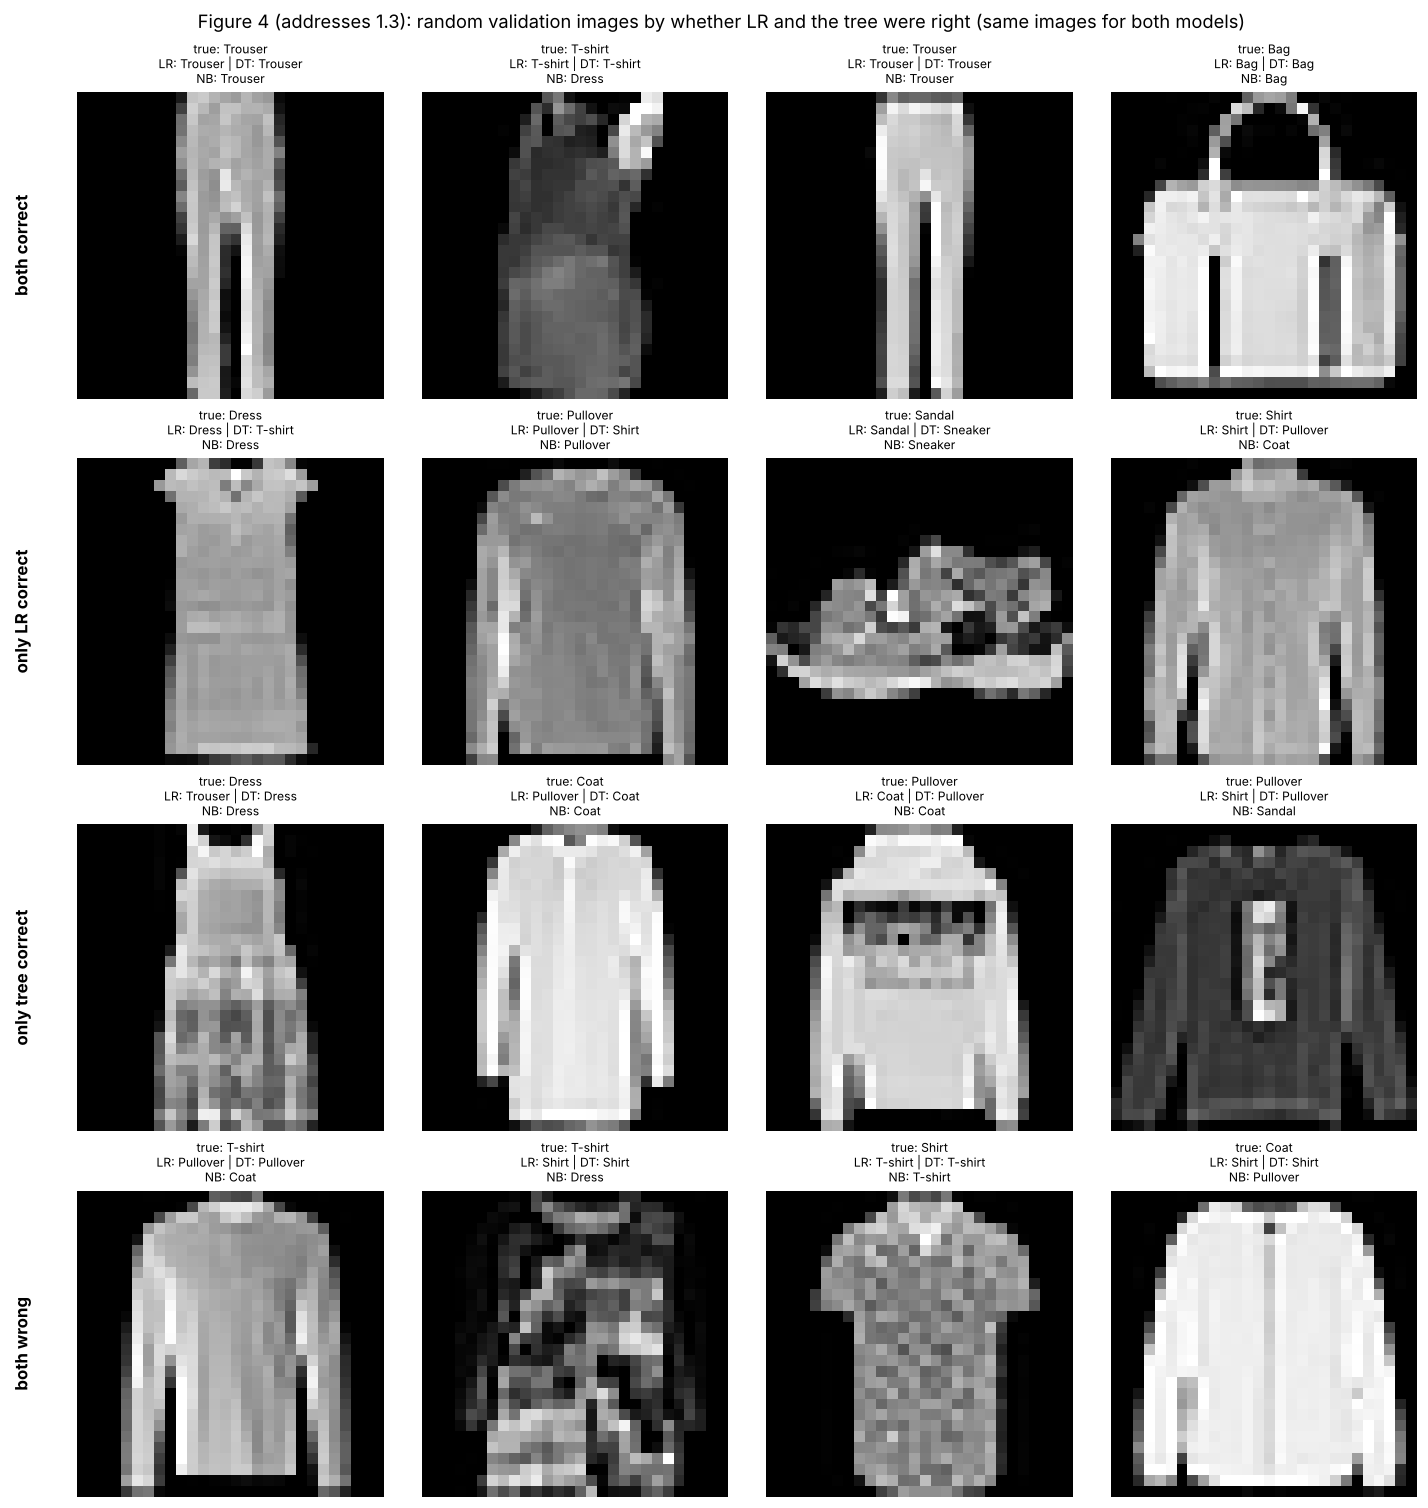

Classes from hardest to easiest (validation, mean F1 over the three models)


class,mean F1 over 3 models
Shirt,0.468
Pullover,0.670
Coat,0.687
T-shirt/top,0.762
Sandal,0.791
Dress,0.796
Sneaker,0.843
Bag,0.899
Ankle boot,0.907
Trouser,0.955


In [8]:
# ---------------- Same images, two models: agreement table and a fixed random example grid (addresses 1.3) -----------------
lr_ok = PRED_VA["LR"] == yva; dt_ok = PRED_VA["DT"] == yva
agree = pd.DataFrame({"DT correct": [int((lr_ok & dt_ok).sum()), int((lr_ok & ~dt_ok).sum())],
                      "DT wrong":   [int((~lr_ok & dt_ok).sum()), int((~lr_ok & ~dt_ok).sum())]}, index=["LR correct", "LR wrong"])
print("Agreement of LR and tree on the SAME 10,000 validation images"); display(agree)
ev.log_experiment(id="P1-ERR-01", part_task="1.3", question="Do LR and the tree fail on the same validation images?",
    hypothesis="Largely the same hard classes, but different individual images, because the models use pixels differently.", changed_variable="model family",
    fixed_conditions="identical validation images", split="validation 10k", seed=SEED_NOTE, configuration=f"{LABEL['LR']} vs {LABEL['DT']}",
    metric="2x2 agreement counts", result=agree.to_dict(), output_path="results/part1/agreement_lr_dt.csv", notes="")
agree.to_csv(RES_DIR / "agreement_lr_dt.csv")

rng = np.random.default_rng(SEED)           # fixed seed: images are drawn at random, not hand-picked
groups = {"both correct": np.flatnonzero(lr_ok & dt_ok), "only LR correct": np.flatnonzero(lr_ok & ~dt_ok),
          "only tree correct": np.flatnonzero(~lr_ok & dt_ok), "both wrong": np.flatnonzero(~lr_ok & ~dt_ok)}
fig, ax = plt.subplots(4, 4, figsize=(13, 13.6), constrained_layout=True)
for r, (g, idx) in enumerate(groups.items()):
    chosen = rng.choice(idx, size=min(4, len(idx)), replace=False)
    for c in range(4):
        a = ax[r, c]; a.axis("off")
        if c < len(chosen):
            i = chosen[c]; a.imshow(Xva[i].reshape(28, 28), cmap="gray")
            a.set_title(f"true: {SHORT[yva[i]]}\nLR: {SHORT[PRED_VA['LR'][i]]} | DT: {SHORT[PRED_VA['DT'][i]]}\nNB: {SHORT[PRED_VA['NB'][i]]}", fontsize=8)
    ax[r, 0].text(-0.15, 0.5, g, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
fig.suptitle("Figure 4 (addresses 1.3): random validation images by whether LR and the tree were right (same images for both models)", fontsize=12)
save_fig(fig, "fig4_error_examples", "1.3", "Four randomly drawn validation images (seed 708) per agreement group; titles give the true class and the predictions of LR, tree and NB.")
plt.show()

rank = wide[["class"]].copy(); rank["mean F1 over 3 models"] = wide[["LR F1", "DT F1", "NB F1"]].mean(axis=1); rank = rank.sort_values("mean F1 over 3 models")
print("Classes from hardest to easiest (validation, mean F1 over the three models)"); display(rank.style.format({"mean F1 over 3 models": "{:.3f}"}).hide(axis="index"))

**Figure 4 (addresses 1.3).** Four validation images drawn at random (seed 708, not hand-picked) from each of four groups defined by whether logistic regression and the tree were right. Both models are shown the same images. The third line of each title gives the naive Bayes prediction.

### Interpretation of 1.3
**Where errors concentrate (hypothesis supported).** Hardest classes by mean F1 over the three models start with Shirt, then Pullover and Coat (see the ranking table), and the most frequent LR confusions all lie inside the upper-body group: Shirt predicted as T-shirt (159 of 1,000), Shirt as Pullover (113), Pullover as Coat (109), Pullover as Shirt (104), Coat as Shirt (102), Shirt as Coat (86). The tree's top confusions are the same pairs (Shirt to T-shirt 191, Coat to Pullover 161, Shirt to Pullover 136), only larger. Trouser, Bag and the footwear classes have high recall for LR and the tree. For naive Bayes, footwear errors are spread more widely, so the footwear-stays-inside-footwear part of my hypothesis is confirmed for LR and the tree from the confusion matrices; I did not check it separately for NB.

**Same images or not?** On the same 10,000 validation images, both LR and the tree are right on 7,653, both wrong on 916, only LR right on 900 and only the tree right on 531. So about half of the tree's 1,816 errors are shared with LR (916 of 1,816) and half are not: the models make errors in the same hard regions but not on the same individual images. The 916 shared errors are a lower bound on what is intrinsically ambiguous at this representation; the random examples in Figure 4 are drawn with a fixed seed, so they illustrate and do not prove the groups (I did not look for a systematic cause in the images beyond the class pairs above).

**What this suggests.** Upper-body garments differ in fine texture, sleeve length and collar shape that raw pixels and a linear or axis-aligned model capture poorly; this is a hypothesis about the representation, not something these experiments test directly.

## 1.5 Decisions and costs: a binary problem of our own

**Problem (derived from the ten classes).** *Shirt versus everything else.* Imagine an online shop that files each photographed garment into a category automatically. A photo predicted as **Shirt** goes into the Shirts listing.

* **Positive** = Shirt (class 6); **negative** = the other nine classes. On validation this is 1,000 positives and 9,000 negatives, so **prevalence is 10%**. Always predicting "not a shirt" is therefore already 90% accurate and useless, the lecture's imbalanced-data warning, so accuracy alone is not an adequate metric here.
* **Two errors with different costs.** A *false negative* (a shirt is hidden in the wrong listing) loses a sale; a *false positive* (something else appears among the shirts) causes complaints and returns. The costs below are **illustrative assumptions, not measured data**. Costs are in arbitrary units per item; correct decisions cost 0.

| Scenario | Cost of a false negative | Cost of a false positive |
|---|---|---|
| A: balanced | 1 | 1 |
| B: a missed shirt is 5× worse | 5 | 1 |
| C: a false alarm is 5× worse | 1 | 5 |

**Score and threshold.** Each model's score for this problem is its predicted probability of class *Shirt* (the probability mass the multi-class model assigns to that class); an image is flagged as Shirt if the score is at least a threshold *t*. Lowering *t* flags more images: fewer false negatives, more false positives. The default is *t* = 0.5. (The tree's score is the training-class proportion in its leaf, so it takes few distinct values; naive Bayes probabilities are typically over-confident.)

**Hypotheses.** (i) The ROC curves of the three models differ, with LR the best; (ii) the cost-minimising threshold moves **down** when missed shirts are costlier (B) and **up** when false alarms are costlier (C); (iii) if LR's probabilities were well calibrated, the optimal threshold would be close to *c<sub>FP</sub> / (c<sub>FP</sub> + c<sub>FN</sub>)*, i.e. 0.5, 0.167 and 0.833 for A, B and C.

**Rule R1:** the thresholds are chosen on the validation images only. **Metric:** TPR, FPR, precision, ROC AUC, and expected cost per item on validation.

In [9]:
SHIRT = CLASS_NAMES.index("Shirt"); y_bin = (yva == SHIRT).astype(int); N = len(y_bin); prev = y_bin.mean()
SCORES = {k: m.predict_proba(Xva)[:, SHIRT] for k, m in SEL_MODELS.items()}
SCEN = {"A: balanced (FN 1, FP 1)": (1, 1), "B: missed shirt 5x worse (FN 5, FP 1)": (5, 1), "C: false alarm 5x worse (FN 1, FP 5)": (1, 5)}
TS = np.linspace(0, 1, 1001)

def counts_at(score, t):
    pred = score >= t
    return int((pred & (y_bin == 1)).sum()), int((pred & (y_bin == 0)).sum()), int((~pred & (y_bin == 1)).sum()), int((~pred & (y_bin == 0)).sum())  # TP FP FN TN

CURVE = {k: np.array([counts_at(s, t) for t in TS]) for k, s in SCORES.items()}   # columns TP FP FN TN for every threshold
def cost_curve(k, cfn, cfp): c = CURVE[k]; return (cfn * c[:, 2] + cfp * c[:, 1]) / N

# ---- ROC / AUC on validation
ROC = {k: roc_curve(y_bin, s) for k, s in SCORES.items()}; AUC = {k: roc_auc_score(y_bin, s) for k, s in SCORES.items()}
print("Shirt-vs-rest, validation: prevalence", prev, "| 'never shirt' accuracy", 1 - prev)
print("ROC AUC:", {LABEL[k]: round(v, 4) for k, v in AUC.items()})

# ---- LR at a few thresholds
rows = []
for t in [0.05, 0.1, 0.167, 0.2, 0.3, 0.5, 0.7, 0.833, 0.9]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    rows.append({"threshold": t, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "TPR (recall)": TP / (TP + FN), "FPR": FP / (FP + TN),
                 "precision": TP / max(TP + FP, 1), "accuracy": (TP + TN) / N})
thr_table = pd.DataFrame(rows); thr_table.to_csv(RES_DIR / "shirt_threshold_table_lr.csv", index=False)
print("Logistic regression: confusion counts and rates at several thresholds (validation)")
display(thr_table.style.format({"threshold": "{:.3f}", "TPR (recall)": "{:.3f}", "FPR": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.4f}"}).hide(axis="index"))

# ---- cost-minimising thresholds on validation
rows = []; BEST_T = {}
for sname, (cfn, cfp) in SCEN.items():
    for k in ["LR", "DT", "NB"]:
        cc = cost_curve(k, cfn, cfp); j = int(np.argmin(cc)); t_star = float(TS[j])
        if k == "LR": BEST_T[sname] = t_star
        rows.append({"scenario": sname, "model": k, "best threshold": t_star, "expected cost @ best": cc[j], "expected cost @ 0.5": cc[500],
                     "never-shirt baseline": cfn * prev, "calibrated-theory threshold": cfp / (cfp + cfn)})
cost_table = pd.DataFrame(rows); cost_table.to_csv(RES_DIR / "shirt_cost_table.csv", index=False)
print("Expected cost per item on validation (lower is better)")
display(cost_table.style.format({"best threshold": "{:.3f}", "expected cost @ best": "{:.4f}", "expected cost @ 0.5": "{:.4f}", "never-shirt baseline": "{:.4f}", "calibrated-theory threshold": "{:.3f}"}).hide(axis="index"))
for sname in SCEN:
    ev.log_experiment(id=f"P1-THR-{sname[0]}", part_task="1.5", question="How does the decision threshold trade false negatives against false positives, and where is the cost minimum?",
        hypothesis="Optimal threshold moves down when FN is costlier and up when FP is costlier; near cFP/(cFP+cFN) if calibrated.", changed_variable="decision threshold (and cost ratio)",
        fixed_conditions="Shirt-vs-rest from selected LR scores; same validation images", split="validation 10k", seed=SEED_NOTE, configuration=sname,
        metric="expected cost per item; TPR/FPR", result=f"best threshold (LR) = {BEST_T[sname]:.3f}", output_path="results/part1/shirt_cost_table.csv", notes="costs are illustrative assumptions")

Shirt-vs-rest, validation: prevalence 0.1 | 'never shirt' accuracy 0.9
ROC AUC: {'Logistic regression (C=0.1)': 0.9435, 'Decision tree (max_depth=12)': 0.8831, 'Gaussian NB (var_smoothing=0.1)': 0.6944}
Logistic regression: confusion counts and rates at several thresholds (validation)


threshold,TP,FP,FN,TN,TPR (recall),FPR,precision,accuracy
0.050,944,2055,56,6945,0.944,0.228,0.315,0.7889
0.100,889,1418,111,7582,0.889,0.158,0.385,0.8471
0.167,824,970,176,8030,0.824,0.108,0.459,0.8854
0.200,793,829,207,8171,0.793,0.092,0.489,0.8964
0.300,699,530,301,8470,0.699,0.059,0.569,0.9169
0.500,525,230,475,8770,0.525,0.026,0.695,0.9295
0.700,339,71,661,8929,0.339,0.008,0.827,0.9268
0.833,174,17,826,8983,0.174,0.002,0.911,0.9157
0.900,69,7,931,8993,0.069,0.001,0.908,0.9062


Expected cost per item on validation (lower is better)


scenario,model,best threshold,expected cost @ best,expected cost @ 0.5,never-shirt baseline,calibrated-theory threshold
"A: balanced (FN 1, FP 1)",LR,0.580,0.0692,0.0705,0.1000,0.500
"A: balanced (FN 1, FP 1)",DT,0.601,0.0754,0.0790,0.1000,0.500
"A: balanced (FN 1, FP 1)",NB,1.000,0.1140,0.1189,0.1000,0.500
"B: missed shirt 5x worse (FN 5, FP 1)",LR,0.164,0.1841,0.2605,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",DT,0.196,0.2118,0.2922,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",NB,0.001,0.4400,0.4441,0.5000,0.167
"C: false alarm 5x worse (FN 1, FP 5)",LR,0.838,0.0902,0.1625,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",DT,0.924,0.1117,0.1818,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",NB,1.000,0.2336,0.2693,0.1000,0.833


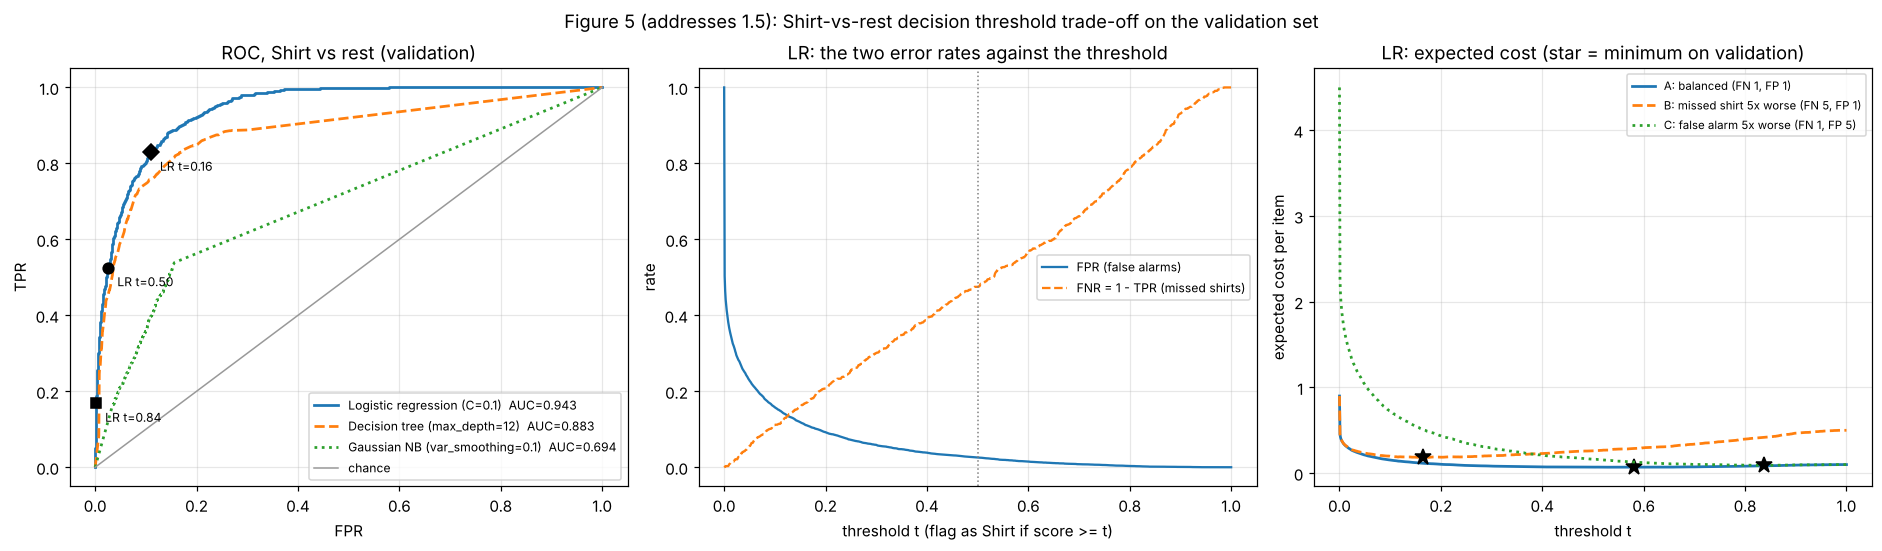

LR, scenario A: balanced (FN 1, FP 1): threshold 0.580 -> TP 455, FP 147, FN 545, TN 8853  (TPR 0.455, FPR 0.016, precision 0.756)
LR, scenario B: missed shirt 5x worse (FN 5, FP 1): threshold 0.164 -> TP 829, FP 986, FN 171, TN 8014  (TPR 0.829, FPR 0.110, precision 0.457)
LR, scenario C: false alarm 5x worse (FN 1, FP 5): threshold 0.838 -> TP 168, FP 14, FN 832, TN 8986  (TPR 0.168, FPR 0.002, precision 0.923)


In [10]:
# ---------------- Figure 5: ROC and threshold trade-off on validation (addresses 1.5) -----------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), constrained_layout=True)
styles = {"LR": ("-", "o"), "DT": ("--", "s"), "NB": (":", "^")}
for k in ["LR", "DT", "NB"]:
    f, tpr, _ = ROC[k]; ax[0].plot(f, tpr, ls=styles[k][0], lw=1.8, label=f"{LABEL[k]}  AUC={AUC[k]:.3f}")
ax[0].plot([0, 1], [0, 1], color="0.6", lw=1, label="chance")
for t, mk in [(0.5, "o"), (BEST_T["B: missed shirt 5x worse (FN 5, FP 1)"], "D"), (BEST_T["C: false alarm 5x worse (FN 1, FP 5)"], "s")]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t); ax[0].plot(FP / (FP + TN), TP / (TP + FN), mk, color="k", ms=7); ax[0].annotate(f"LR t={t:.2f}", (FP / (FP + TN), TP / (TP + FN)), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC, Shirt vs rest (validation)"); ax[0].legend(loc="lower right", fontsize=8)

c = CURVE["LR"]; ax[1].plot(TS, c[:, 1] / (c[:, 1] + c[:, 3]), "-", label="FPR (false alarms)"); ax[1].plot(TS, c[:, 2] / (c[:, 0] + c[:, 2]), "--", label="FNR = 1 - TPR (missed shirts)")
ax[1].axvline(0.5, color="0.5", lw=1, ls=":"); ax[1].set_xlabel("threshold t (flag as Shirt if score >= t)"); ax[1].set_ylabel("rate"); ax[1].set_title("LR: the two error rates against the threshold"); ax[1].legend(fontsize=8)

for (sname, (cfn, cfp)), ls in zip(SCEN.items(), ["-", "--", ":"]):
    cc = cost_curve("LR", cfn, cfp); ax[2].plot(TS, cc, ls=ls, lw=1.8, label=sname); j = int(np.argmin(cc)); ax[2].plot(TS[j], cc[j], "k*", ms=11)
ax[2].set_xlabel("threshold t"); ax[2].set_ylabel("expected cost per item"); ax[2].set_title("LR: expected cost (star = minimum on validation)"); ax[2].legend(fontsize=7.5)
fig.suptitle("Figure 5 (addresses 1.5): Shirt-vs-rest decision threshold trade-off on the validation set", fontsize=12)
save_fig(fig, "fig5_threshold_tradeoff", "1.5", "ROC curves of the three models; LR error rates against threshold; LR expected cost per item against threshold for three cost scenarios (validation).")
plt.show()

for sname, t in BEST_T.items():
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    print(f"LR, scenario {sname}: threshold {t:.3f} -> TP {TP}, FP {FP}, FN {FN}, TN {TN}  (TPR {TP/(TP+FN):.3f}, FPR {FP/(FP+TN):.3f}, precision {TP/max(TP+FP,1):.3f})")

**Figure 5 (addresses 1.5).** Left: ROC curves for the Shirt-versus-rest decision on the validation images (line styles identify the models; black markers show logistic-regression operating points at *t* = 0.5 and at the cost-optimal thresholds of scenarios B and C). Middle: logistic regression's false-positive and false-negative rates against the threshold. Right: expected cost per item against the threshold for the three cost scenarios; stars mark the minimum. All validation data, selected models, seed 708.

### Interpretation of 1.5
**Baseline and metric.** With 10% Shirts, 'never Shirt' is 90% accurate (cost 0.100 in scenario A), and LR's accuracy at t=0.5 is 0.9295. Accuracy therefore barely separates a useful filter from a trivial one, so I report TPR, FPR, precision and expected cost.

**Ranking of models (hypothesis i).** ROC AUC for Shirt-vs-rest on validation is **0.944 for LR, 0.883 for the tree and 0.694 for NB**, so LR ranks shirts best, consistent with the multi-class ordering. NB's score is so over-confident that the best expected-cost threshold is at or beyond the ends of the range: in scenario A it is no better than 'never Shirt' (0.1140 versus 0.100), and in scenario C it is worse (0.2336 versus 0.100). LR beats the 'never Shirt' baseline in A (0.0692 versus 0.100), B (0.1841 versus 0.500) and, by a small margin, C (0.0902 versus 0.100); at t=0.5 in C it is worse than the baseline (0.1625 versus 0.100).

**Threshold trade-off.** For LR, lowering t from 0.5 to 0.1 raises TPR from 0.525 to 0.889 but also FPR from 0.026 to 0.158 and lowers precision from 0.695 to 0.385: the two errors trade directly, as expected. At t=0.5 the filter misses 475 of 1,000 shirts.

**Cost-dependent threshold (hypothesis ii supported).** The cost-minimising LR threshold on validation is 0.580 for A, **0.164 for B** (missed shirts 5x worse) and **0.838 for C** (false alarms 5x worse): it moves down when misses are costly and up when false alarms are costly. The expected cost at t=0.5 would be 0.2605 in B and 0.1625 in C versus 0.1841 and 0.0902 at the best threshold, so the default threshold is clearly wrong for unequal costs.

**Calibration (hypothesis iii).** The optimal thresholds (0.164, 0.838, 0.580) are close to the calibrated-theory values 0.167, 0.833, 0.500, so LR's probabilities seem reasonably calibrated for this problem; for the tree they are further away (0.196, 0.924, 0.601), and NB is not usable. I did not compute a calibration curve, so 'reasonably calibrated' is an inference from the thresholds only.

**Caveats.** The costs are assumptions chosen for illustration; real costs would change the thresholds. The thresholds are tuned on the same validation images they are evaluated on, so the stated costs are slightly optimistic; the frozen plan evaluates them once on test.

## Part 1 summary and evidence index

| Task | Evidence in this notebook |
|---|---|
| 1.1 | Model table and justification; sweep tables |
| 1.2 | Overall accuracy table with intervals; class-level table with supports; Figure 2 |
| 1.3 | Figure 3 (confusion matrices), Figure 4 (same images, both models), agreement table, hardest-to-easiest ranking |
| 1.4 | Sweep tables for the three models; Figure 1; tree seed table |
| 1.5 | ROC and threshold tables; cost table; Figure 5 |

### Limitations of Part 1
* One fixed split (seed 708) and a single validation set: differences below about 0.5 points are not reliable.
* LR at C=1 and 10 did not converge in 400 iterations, so those two points are not exact optima.
* Grids are coarse and the selection rule (simplest within 0.1 points) is a convention I chose before the runs.
* Only the tree has seed variability measured; its spread is negligible but this says nothing about data-split variability.
* The Shirt-vs-rest costs are illustrative assumptions, and thresholds are tuned and evaluated on the same validation data.
* No calibration curve was computed; no test data has been used.

## Frozen test plan for Part 1 (rules R6, R7)

The next cell records, **before any test image is used**, exactly what will be evaluated on the sealed test set: the three models with the settings selected above (already fitted on the 50,000 training images, never refitted), the metrics, and the Shirt-versus-rest thresholds chosen on validation. The plan is written to `results/test_plan_part1.json`; if the file already exists it is *checked, not overwritten*, so the plan cannot drift after seeing results. The test evaluation itself is guarded by `RUN_FINAL_TEST` and is only to be switched on **once, after all parts are finished**; ideas prompted by test errors would be future hypotheses, not validated improvements (R7).

In [11]:
test_plan = {
    "part": 1, "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)", "fit_data": "train 50,000 (no refit)",
    "models": {"logistic_regression": {"C": SEL["LR"], "max_iter": LR_MAXIT, "seed": "deterministic"},
               "decision_tree": {"criterion": "entropy", "max_depth": SEL["DT"], "random_state": SEED},
               "gaussian_nb": {"var_smoothing": SEL["NB"]}},
    "metrics": ["overall accuracy with 95% Wilson interval", "per-class precision/recall/F1 with support", "confusion matrix",
                "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"],
    "shirt_vs_rest_thresholds_selected_on_validation": BEST_T, "cost_scenarios": {k: list(v) for k, v in SCEN.items()},
}
plan_path = ROOT / "results" / "test_plan_part1.json"
if plan_path.exists():
    frozen = json.loads(plan_path.read_text())
    assert frozen == json.loads(json.dumps(test_plan)), "The frozen test plan differs from the current selection: do not edit the plan after seeing results (R6/R7)."
    print("Frozen test plan found and matches the current selection.")
else:
    plan_path.write_text(json.dumps(test_plan, indent=2)); print("Test plan written (frozen).")
print(json.dumps(test_plan, indent=2))

Frozen test plan found and matches the current selection.
{
  "part": 1,
  "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)",
  "fit_data": "train 50,000 (no refit)",
  "models": {
    "logistic_regression": {
      "C": 0.1,
      "max_iter": 400,
      "seed": "deterministic"
    },
    "decision_tree": {
      "criterion": "entropy",
      "max_depth": 12,
      "random_state": 708
    },
    "gaussian_nb": {
      "var_smoothing": 0.1
    }
  },
  "metrics": [
    "overall accuracy with 95% Wilson interval",
    "per-class precision/recall/F1 with support",
    "confusion matrix",
    "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"
  ],
  "shirt_vs_rest_thresholds_selected_on_validation": {
    "A: balanced (FN 1, FP 1)": 0.58,
    "B: missed shirt 5x worse (FN 5, FP 1)": 0.164,
    "C: false alarm 5x worse (FN 1, FP 5)": 0.838
  },
  "cost_scenarios": {
    "A: balanced (FN 1, FP 1)": [
      1,
      1
    ],


In [12]:
RUN_FINAL_TEST = False   # switch on ONCE, after all parts are finished (R6, R7)

def evaluate_frozen(X, y, label, log=False):
    """Evaluate the frozen Part 1 models on (X, y). Used on validation as a dry run, and on test only when RUN_FINAL_TEST is True."""
    yb = (y == SHIRT).astype(int); out = []
    for k, m in SEL_MODELS.items():
        p = m.predict(X); correct = int((p == y).sum()); lo, hi = ev.wilson_interval(correct, len(y))
        row = {"model": LABEL[k], "accuracy": correct / len(y), "95% interval": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": ev.per_class_table(y, p)["F1"].mean()}
        s = m.predict_proba(X)[:, SHIRT]; row["Shirt ROC AUC"] = roc_auc_score(yb, s); out.append(row)
        if log:
            ev.log_experiment(id=f"P1-TEST-{k}", part_task="1.2", question="Final estimate of the frozen Part 1 model", hypothesis="Test accuracy close to validation accuracy.",
                changed_variable="none", fixed_conditions="frozen plan results/test_plan_part1.json", split="official test 10k", seed=SEED_NOTE, configuration=LABEL[k],
                metric="accuracy", result=f"{row['accuracy']:.4f}", output_path="results/part1/final_test_part1.csv", notes="evaluated once, no tuning afterwards (R7)")
    res = pd.DataFrame(out); print(f"Frozen models on {label}"); display(res.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}", "Shirt ROC AUC": "{:.4f}"}).hide(axis="index"))
    return res

dry = evaluate_frozen(Xva, yva, "VALIDATION (dry run of the evaluation code; the test set is not touched)")
if RUN_FINAL_TEST:
    Xte, yte = _sealed_test
    final = evaluate_frozen(Xte, yte, "TEST (final estimate, evaluated once)", log=True); final.to_csv(RES_DIR / "final_test_part1.csv", index=False)
else:
    print("RUN_FINAL_TEST is False: the sealed test set has not been used.")

Frozen models on VALIDATION (dry run of the evaluation code; the test set is not touched)


model,accuracy,95% interval,macro-F1,Shirt ROC AUC
Logistic regression (C=0.1),0.8553,"[0.8483, 0.8621]",0.8547,0.9435
Decision tree (max_depth=12),0.8184,"[0.8107, 0.8258]",0.8168,0.8831
Gaussian NB (var_smoothing=0.1),0.6746,"[0.6654, 0.6837]",0.6618,0.6944


RUN_FINAL_TEST is False: the sealed test set has not been used.


In [13]:
# ---------------- bookkeeping: figure index and the Part 1 slice of the experiment register -----------------
pd.DataFrame(FIG_INDEX).to_csv(FIG_DIR / "part1_figure_index.csv", index=False)
reg = pd.read_csv(ev.REGISTER_PATH, dtype=str).fillna("")
print(f"{reg['id'].str.startswith('P1-').sum()} Part 1 experiments in results/experiment_register.csv; first rows:")
display(reg[reg["id"].str.startswith("P1-")][["id", "part_task", "changed_variable", "configuration", "result"]].head(12))

36 Part 1 experiments in results/experiment_register.csv; first rows:


,id,part_task,changed_variable,configuration,result
0,P1-LR-01,1.4,C,C=0.0001,train=0.7562; val=0.7509; converged=True
1,P1-LR-02,1.4,C,C=0.001,train=0.8217; val=0.8162; converged=True
2,P1-LR-03,1.4,C,C=0.01,train=0.8569; val=0.8487; converged=True
3,P1-LR-04,1.4,C,C=0.1,train=0.8747; val=0.8553; converged=True
4,P1-LR-05,1.4,C,C=1.0,train=0.8820; val=0.8528; converged=False
5,P1-LR-06,1.4,C,C=10.0,train=0.8828; val=0.8528; converged=False
6,P1-DT-01,1.4,max_depth,max_depth=1,train=0.1989; val=0.1985; leaves=2
7,P1-DT-02,1.4,max_depth,max_depth=2,train=0.3422; val=0.3434; leaves=4
8,P1-DT-03,1.4,max_depth,max_depth=3,train=0.5164; val=0.5168; leaves=8
9,P1-DT-04,1.4,max_depth,max_depth=4,train=0.6776; val=0.6814; leaves=16
